# Tuần 10 — Thực hành bootstrap và kiểm định giả thuyết

Mục tiêu: lấy mẫu lại, tính sai số chuẩn và khoảng tin cậy; tính giá trị p và kết luận trong các bài kiểm định đơn giản.

 Nếu thiếu thư viện, bỏ dấu `#` ở ô cài đặt, chạy một lần rồi khởi động lại kernel.


In [1]:
# %pip install numpy scipy matplotlib plotnine


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, binom, binomtest, hypergeom
from itertools import combinations

alpha = 0.05
muc_tin_cay = 0.95


## Công thức dùng trong buổi thực hành

- Bootstrap: rút có hoàn lại $n$ quan sát từ mẫu gốc, tính thống kê, lặp $B$ lần.
- Sai số chuẩn bootstrap là độ lệch chuẩn của **các thống kê bootstrap**, tính bằng `std(ddof=1)`.
- Khoảng tin cậy 95% theo phân vị: `np.quantile(thong_ke_boot, [0.025, 0.975])`.
- Kiểm định một tỷ lệ: dưới $H_0:p=p_0$, $K\sim\mathrm{Binomial}(n,p_0)$; xấp xỉ chuẩn dùng $Z=(\hat p-p_0)/\sqrt{p_0(1-p_0)/n}$.
- Giá trị p là xác suất, dưới $H_0$, của kết quả ít nhất cực đoan như quan sát. Bác bỏ $H_0$ nếu p-value $\le\alpha$.

Mỗi bài kiểm định cần nêu tham số, $H_0,H_A$, điều kiện, thống kê, giá trị p và kết luận theo bối cảnh. Không bác bỏ $H_0$ không có nghĩa là chứng minh $H_0$ đúng.


## Bài 1 — Bootstrap tỷ lệ linh kiện đạt chuẩn


Mẫu ngẫu nhiên gồm 100 linh kiện có 62 linh kiện đạt chuẩn. Giả sử các kết quả độc lập và mẫu phản ánh tương đối tốt lô hàng.
Ước lượng tỷ lệ đạt chuẩn $p$, sai số chuẩn và khoảng tin cậy 95% theo phân vị.


**Thao tác:** nhập mẫu 0–1 → tính tỷ lệ mẫu → lấy mẫu lại có hoàn lại → tính sai số chuẩn → lấy hai phân vị.


In [2]:
x = np.r_[np.ones(62), np.zeros(38)]
n = len(x)
p_hat = x.mean()
B = 20_000
rng = np.random.default_rng(20261010)
mau_boot = rng.choice(x, size=(B, n), replace=True)
p_boot = mau_boot.mean(axis=1)
se_boot = p_boot.std(ddof=1)
khoang = np.quantile(p_boot, [0.025, 0.975])
se_cong_thuc = np.sqrt(p_hat * (1 - p_hat) / n)
print("n =", n, "; tỷ lệ mẫu =", p_hat)
print("SE bootstrap =", se_boot, "; SE theo công thức =", se_cong_thuc)
print("Khoảng tin cậy bootstrap 95%:", khoang)


n = 100 ; tỷ lệ mẫu = 0.62
SE bootstrap = 0.04856669904330331 ; SE theo công thức = 0.048538644398046386
Khoảng tin cậy bootstrap 95%: [0.52    0.71025]


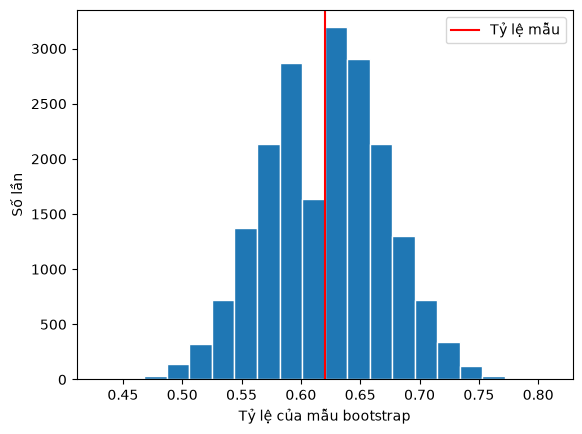

In [3]:
plt.hist(p_boot, bins=20, edgecolor="white")
plt.axvline(p_hat, color="red", label="Tỷ lệ mẫu")
plt.xlabel("Tỷ lệ của mẫu bootstrap")
plt.ylabel("Số lần")
plt.legend()
plt.show()


**Đối chiếu và tự nhận xét:** $\hat p=0.62$; SE khoảng $0.0486$; khoảng tin cậy khoảng $[0.52;0.71]$. Đây là khoảng ước lượng tỷ lệ đạt chuẩn của tổng thể. 


## Bài 2a — Bootstrap hệ số góc: ví dụ đơn giản


Dữ liệu giả định gồm sáu thiết bị: $x$ là số tác vụ đồng thời, $y$ là thời gian xử lý (ms). Ước lượng hệ số góc tổng thể bằng mô hình tuyến tính và khoảng tin cậy bootstrap.
Giả sử các cặp độc lập, đại diện cho đối tượng nghiên cứu; bộ số liệu nhỏ chỉ để luyện thao tác.


**Thao tác:** nhập các cặp → tính hệ số góc → lấy mẫu lại cả cặp → khớp lại đường thẳng → tính SE và khoảng.


In [5]:
xy = np.array([[1, 3], [2, 4], [3, 7], [4, 8], [5, 11], [6, 12]], dtype=float)
def he_so_goc(a):
    x, y = a.T
    dx = x - x.mean()
    return np.sum(dx * (y - y.mean())) / np.sum(dx**2)

b1 = he_so_goc(xy)
rng = np.random.default_rng(10)
b_boot = []
so_mau_suy_bien = 0
for _ in range(10_000):
    mau = xy[rng.integers(len(xy), size=len(xy))]
    if np.ptp(mau[:, 0]) == 0:
        so_mau_suy_bien += 1
        continue  # Không khớp được hệ số góc khi mọi x giống nhau.
    b_boot.append(he_so_goc(mau))
b_boot = np.array(b_boot)
print("Hệ số góc =", b1)
print("Số mẫu không khớp được:", so_mau_suy_bien)
print("SE =", b_boot.std(ddof=1))
print("Khoảng 95%:", np.quantile(b_boot, [0.025, 0.975]))


Hệ số góc = 1.9142857142857144
Số mẫu không khớp được: 1
SE = 0.15286853390024802
Khoảng 95%: [1.70588235 2.25      ]


**Đối chiếu và tự nhận xét:** Hệ số góc khoảng 1.914 ms/tác vụ. Khi số tác vụ tăng một đơn vị, thời gian dự đoán tăng khoảng 1.914 ms. Phải rút cả cặp để giữ liên hệ giữa x và y. Kết quả bootstrap ở đây tính trên các mẫu khớp được; không xem dữ liệu sáu thiết bị là cơ sở mạnh để suy rộng.


## Bài 2b — Bootstrap hệ số góc với mpg (theo slide)

Dùng `from plotnine.data import mpg`: 234 dòng, X = `displ` (dung tích động cơ, lít), Y = `hwy` (dặm/gallon trên đường cao tốc). Ước lượng hệ số góc tổng thể trong mô hình hồi quy tuyến tính, SE và khoảng tin cậy 95%.

Mỗi lần lấy mẫu có hoàn lại 234 dòng, giữ nguyên cả cặp (X, Y), không rút hai cột độc lập. Dùng seed 20261010 và 20.000 lần lặp như slide. Suy rộng cần giả định các cặp độc lập và mẫu phù hợp với tổng thể nghiên cứu.


In [29]:
# Chuẩn bị dữ liệu và tính hệ số góc
import numpy as np
import matplotlib.pyplot as plt
from plotnine.data import mpg

xy_mpg = mpg[['displ', 'hwy']].to_numpy()

def slope(a):
    x = a[:, 0]
    y = a[:, 1]
    dx = x - x.mean()
    dy = y - y.mean()
    return (dx * dy).sum() / (dx**2).sum()

b1_mpg = slope(xy_mpg)

print("Số quan sát:", len(xy_mpg))
print("Hệ số góc mẫu:", b1_mpg)


Số quan sát: 234
Hệ số góc mẫu: -3.5305888061689226


In [30]:
# Thực hiện bootstrap
rng = np.random.default_rng(20261010)
B = 20_000

b_boot_mpg = []

for i in range(B):
    indices = rng.integers(len(xy_mpg), size=len(xy_mpg))
    xy_star = xy_mpg[indices]
    b_boot_mpg.append(slope(xy_star))

b_boot_mpg = np.array(b_boot_mpg)


In [31]:
# Sai số chuẩn và khoảng tin cậy

se_mpg = b_boot_mpg.std(ddof=1)
ci_mpg = np.quantile(b_boot_mpg, [0.025, 0.975])

print(f"Hệ số góc mẫu: {b1_mpg:.3f}")
print(f"Sai số chuẩn bootstrap: {se_mpg:.3f}")
print(f"Khoảng tin cậy 95%: {ci_mpg}")



Hệ số góc mẫu: -3.531
Sai số chuẩn bootstrap: 0.248
Khoảng tin cậy 95%: [-4.02140119 -3.05352211]


In [32]:
# Tính hệ số chặn và chuẩn bị đường hồi quy
x_mpg = xy_mpg[:, 0]
y_mpg = xy_mpg[:, 1]

b0_mpg = y_mpg.mean() - b1_mpg * x_mpg.mean()
x_line = np.array([x_mpg.min(), x_mpg.max()])


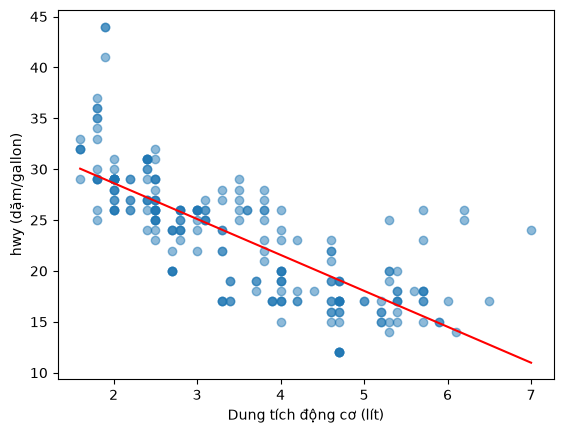

In [33]:
# Vẽ dữ liệu và đường hồi quy
plt.scatter(x_mpg, y_mpg, alpha=0.5)
plt.plot(x_line, b0_mpg + b1_mpg * x_line, color="red")
plt.xlabel("Dung tích động cơ (lít)")
plt.ylabel("hwy (dặm/gallon)")
plt.show()


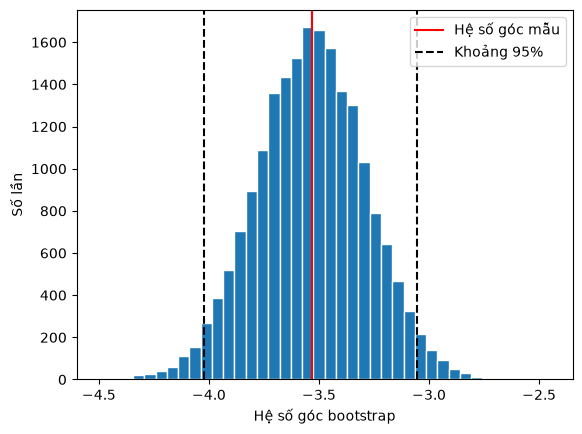

In [34]:
# Vẽ phân phối hệ số góc bootstrap
plt.hist(b_boot_mpg, bins=40, edgecolor="white")

plt.axvline(b1_mpg, color="red", label="Hệ số góc mẫu")
plt.axvline(ci_mpg[0], color="black", linestyle="--",
            label="Khoảng 95%")
plt.axvline(ci_mpg[1], color="black", linestyle="--")

plt.xlabel("Hệ số góc bootstrap")
plt.ylabel("Số lần")
plt.legend()
plt.show()


**Đối chiếu slide:** hệ số góc = -3.531; SE = 0.248; khoảng tin cậy 95% = [-4.021; -3.054].

Dung tích cao hơn 1 lít gắn với mức thấp hơn khoảng 3.531 dặm/gallon trên đường hồi quy đã khớp. Khoảng hoàn toàn âm gợi ý mối liên hệ nghịch dưới các giả định đã nêu; không chứng minh quan hệ nhân quả. Đây là khoảng cho hệ số góc tổng thể, không phải khoảng dự đoán cho một xe.

**Tự nhận xét:** Vì sao phải lấy mẫu lại cả cặp? So sánh dấu và đơn vị hệ số góc với ví dụ sáu thiết bị ở Bài 2a.


## Bài 3 — Tỷ lệ đạt chuẩn có lớn hơn 50%?


Dùng mẫu 100 linh kiện ở Bài 1. Gọi $p$ là tỷ lệ đạt chuẩn của lô hàng.
Kiểm định $H_0:p=0.50$, $H_A:p>0.50$ ở mức 5%.
Tính bằng nhị thức chính xác và xấp xỉ chuẩn; các quan sát được giả sử độc lập, cùng xác suất đạt.


**Thao tác:** đặt giả thuyết → kiểm tra điều kiện → tính thống kê → tính p-value theo từng cách → kết luận.


In [ ]:
# Kiểm định dùng phân phối nhị thức
n, k, p0 = 100, 62, 0.50
p_hat = k / n
p_chinh_xac = binom.sf(k - 1, n, p0)  # P(K >= k)
p_ham = binomtest(k, n, p0, alternative="greater").pvalue
print("Nhị thức chính xác:", p_chinh_xac)
print("Đối chiếu binomtest:", p_ham)
print("Bác bỏ H_0:", p_chinh_xac <= alpha)


Nhị thức chính xác: 0.01048936783892586
Đối chiếu binomtest: 0.01048936783892586
Bác bỏ H_0: True


In [37]:
# Kiểm định dùng xấp xỉ phân phối chuẩn
print("n*p0 =", n*p0, "; n*(1-p0) =", n*(1-p0))
se0 = np.sqrt(p0 * (1 - p0) / n)
z = (p_hat - p0) / se0
p_chuan = norm.sf(z)
moc_z = norm.ppf(1 - alpha)
print("SE dưới H_0 =", se0, "; z =", z)
print("p-value xấp xỉ chuẩn =", p_chuan)
print("Miền bác bỏ: z >=", moc_z, "; thuộc miền:", z >= moc_z)
print("Bác bỏ theo p-value:", p_chuan <= alpha)


n*p0 = 50.0 ; n*(1-p0) = 50.0
SE dưới H_0 = 0.05 ; z = 2.4
p-value xấp xỉ chuẩn = 0.008197535924596131
Miền bác bỏ: z >= 1.6448536269514722 ; thuộc miền: True
Bác bỏ theo p-value: True


**Đối chiếu và tự nhận xét:** Nhị thức: p-value khoảng 0.01049; chuẩn: $z=2.4$, p-value khoảng 0.00820. Cả hai bác bỏ $H_0$: có bằng chứng tỷ lệ đạt chuẩn lớn hơn 50%. Xấp xỉ chuẩn ở đây không hiệu chỉnh liên tục. Vì sao SE kiểm định dùng $p_0$, còn SE bootstrap dùng $\hat p$?


## Bài 4 — Hoán vị so sánh hai thuật toán


12 cảm biến được chia ngẫu nhiên đều vào A/B; A có 5/6 đạt chuẩn, B có 2/6 đạt.
$H_0$: thuật toán không đổi kết quả đạt/không đạt của từng cảm biến; $H_A$: A giúp tăng tỷ lệ đạt.
Dùng $T=\hat p_A-\hat p_B$. Tính theo ba cách: liệt kê mọi phép gán, phân phối siêu bội và mô phỏng.


**Thao tác:** giữ kết quả của 12 cảm biến → tính chênh lệch quan sát → gán lại nhóm 6–6 → đếm đuôi phải → kết luận.


In [38]:
ket_qua = np.array([1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0])
t_obs = ket_qua[:6].mean() - ket_qua[6:].mean()
T = []
for nhom_a in combinations(range(12), 6):
    mask = np.zeros(12, dtype=bool)
    mask[list(nhom_a)] = True
    T.append(ket_qua[mask].mean() - ket_qua[~mask].mean())
T = np.array(T)
p_liet_ke = np.mean(T >= t_obs - 1e-12)
p_sieu_boi = hypergeom.sf(4, 12, 7, 6)  # Ít nhất 5 đạt trong A.
print("T quan sát =", t_obs, "; số cách gán =", len(T))
print("Số cách ít nhất cực đoan:", np.sum(T >= t_obs - 1e-12))
print("p liệt kê =", p_liet_ke, "; p siêu bội =", p_sieu_boi)


T quan sát = 0.5 ; số cách gán = 924
Số cách ít nhất cực đoan: 112
p liệt kê = 0.12121212121212122 ; p siêu bội = 0.1212121212121212


In [39]:
rng = np.random.default_rng(10)
B = 10_000
T_mo_phong = np.empty(B)
for i in range(B):
    mau = rng.permutation(ket_qua)
    T_mo_phong[i] = mau[:6].mean() - mau[6:].mean()
so_cuc_doan = np.sum(T_mo_phong >= t_obs - 1e-12)
p_mo_phong = (so_cuc_doan + 1) / (B + 1)
print("p mô phỏng có hiệu chỉnh +1 =", p_mo_phong)
print("Bác bỏ H_0 theo kết quả chính xác:", p_liet_ke <= alpha)


p mô phỏng có hiệu chỉnh +1 = 0.11788821117888211
Bác bỏ H_0 theo kết quả chính xác: False


**Đối chiếu và tự nhận xét:** $T=0.5$; 112/924 cách thuộc đuôi phải, p chính xác $\approx0.1212$. Chưa đủ bằng chứng A làm tăng tỷ lệ đạt. Mô phỏng chỉ xấp xỉ kết quả chính xác; công thức $(b+1)/(B+1)$ tránh báo p-value bằng 0 khi không gặp kết quả cực đoan.


## Bài 5 — Hoán vị so sánh hai thời gian xử lý


Sáu thiết bị được chia ngẫu nhiên: A có thời gian 8, 9, 10 ms; B có 11, 12, 13 ms.
$H_0$: cấu hình không làm đổi thời gian của từng thiết bị; $H_A$: A làm giảm thời gian.
Dùng $T=\bar x_A-\bar x_B$ và kiểm định phía trái.


**Thao tác:** gộp dữ liệu → tính chênh lệch → liệt kê 20 cách chia → tính tỷ lệ T không lớn hơn quan sát → kết luận.


In [41]:
x = np.array([8, 9, 10, 11, 12, 13])
t_obs = x[:3].mean() - x[3:].mean()
T = []
for nhom_a in combinations(range(6), 3):
    mask = np.zeros(6, dtype=bool)
    mask[list(nhom_a)] = True
    T.append(x[mask].mean() - x[~mask].mean())
T = np.array(T)
p_value = np.mean(T <= t_obs + 1e-12)
print("T quan sát =", t_obs, "; số cách =", len(T), "; p-value =", p_value)


T quan sát = -3.0 ; số cách = 20 ; p-value = 0.05


In [11]:
print("Quyết định:", "Bác bỏ H_0" if p_value <= alpha else "Không bác bỏ H_0")


Quyết định: Bác bỏ H_0


**Đối chiếu và tự nhận xét:** $T=-3$ ms, p-value $=1/20=0.05$. Theo quy tắc $p\le0.05$, bác bỏ $H_0$; dữ liệu ủng hộ A làm giảm thời gian theo thiết kế đã nêu. Nếu câu hỏi là hai cấu hình có khác nhau, hãy dùng $|T|\ge|t_{obs}|$: p-value sẽ bằng bao nhiêu?


## Bài 6 — Tự đọc: ca trực có và không có Gilbert


Bảng trong slide: có Gilbert có 40 ca tử vong/257 ca trực; không có Gilbert có 34/1384.
Đơn vị là ca trực có ít nhất một ca tử vong, không phải từng bệnh nhân.
$H_0:p_G=p_K$, $H_A:p_G\ne p_K$.
Ngoài $H_0$, mô hình hoán vị cần giả định kết quả có thể hoán đổi giữa các ca trực; đây là dữ liệu quan sát.


**Thao tác:** giữ cỡ nhóm và tổng 74 ca có tử vong → tính chênh lệch → lập phân phối siêu bội → cộng xác suất hai phía.


In [12]:
n_g, n_k, so_tu_vong = 257, 1384, 74
t_obs = 40/n_g - 34/n_k
k = np.arange(0, so_tu_vong + 1)
t_k = k/n_g - (so_tu_vong-k)/n_k
xac_suat = hypergeom.pmf(k, n_g+n_k, so_tu_vong, n_g)
p_value = xac_suat[np.abs(t_k) >= abs(t_obs)-1e-12].sum()
print("Chênh lệch =", t_obs, "; p-value =", p_value)
rng = np.random.default_rng(10)
k_mo_phong = rng.hypergeometric(74, 1567, 257, size=500)
t_mo_phong = k_mo_phong/257 - (74-k_mo_phong)/1384
print("Số lần cực đoan trong 500 lần:",
      np.sum(np.abs(t_mo_phong) >= abs(t_obs)-1e-12))


Chênh lệch = 0.1310755493578642 ; p-value = 4.3061271843935704e-15
Số lần cực đoan trong 500 lần: 0


In [13]:
print("Quyết định:", "Bác bỏ H_0" if p_value <= alpha else "Không bác bỏ H_0")


Quyết định: Bác bỏ H_0


**Đối chiếu và tự nhận xét:** Chênh lệch khoảng 13.11 điểm phần trăm; p-value $\approx4.306\times10^{-15}$. Bác bỏ $H_0$ trong mô hình đã giả định. Có liên hệ thống kê không chứng minh quan hệ nhân quả hoặc trách nhiệm pháp lý. Mô phỏng có thể cho 0 lần cực đoan; điều đó không có nghĩa xác suất thực bằng 0.


## Tự thực hành thêm

1. Bài 1: giảm B xuống 500 rồi so với 20.000; nhận xét độ ổn định của SE và khoảng tin cậy.
2. Bài 3: thay bằng 28 sản phẩm lỗi trong 200 sản phẩm, kiểm định tỷ lệ lỗi lớn hơn 10%. Tính cả nhị thức và chuẩn. Đối chiếu p-value khoảng 0.04343 và 0.02967.
3. Bài 5: tính p-value hai phía; đối chiếu 0.10 và nêu kết luận.
4. Chọn một bài kiểm định, viết kết luận bằng lời, nêu rõ giả định và tổng thể muốn suy rộng.
